# DSA4213 Assignment 1: Part II (embedding ablation)

**Before you start:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.

## 1. Check the GPU

In [ ]:
import torch, subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
                     capture_output=True, text=True).stdout)
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then rerun."
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

name, memory.total [MiB]
Tesla T4, 15360 MiB

torch 2.11.0+cu130 | GPU: Tesla T4


## 2. Mount Drive and go to the project folder

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT = "/content/drive/MyDrive/DSA4213/dsa4213-individual-assignment"
assert os.path.exists(f"{PROJECT}/src/train.py"), f"Project not found at {PROJECT}"
os.chdir(PROJECT)
print("Working in", os.getcwd()); print(sorted(os.listdir()))

Mounted at /content/drive
Working in /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment
['.git', '.ipynb_checkpoints', 'README.md', 'configs', 'data', 'requirements.txt', 'results', 'results_run1', 'src']


## 3. Check that the Part II files and Part I results are in Drive
Part II needs the finished Part I LSTM.

`src/models.py` must be the **updated** version: it makes the frozen-embedding LSTMs start from exactly the same weights as the Part I LSTM.

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

import os
needed_code = ["src/embeddings.py", "src/models.py", "src/build_embeddings.py", "src/analyze_part2.py",
               "configs/part2_embeddings.yaml", "configs/part2_lstm_skipgram.yaml",
               "configs/part2_lstm_glove.yaml", "configs/part2_generate.yaml"]
needed_part1 = ["data/processed/vocab.json", "data/glove/glove-wiki-gigaword-200.gz",
                "results/part1_lstm/best.pt", "results/part1_lstm/eval.json",
                "results/part1_lstm/test_token_nll.npy", "results/part1_lstm/train_log.json"]
missing = [p for p in needed_code + needed_part1 if not os.path.exists(p)]
assert not missing, "Missing (copy these into Drive / finish Part I first):\n  " + "\n  ".join(missing)
assert "requires_grad_(not freeze)" in open("src/models.py").read(), \
    "src/models.py is the old version: replace it with the updated Part II file"
assert "skipgram_corpus" in open("src/embeddings.py").read(), \
    "src/embeddings.py is the old version: replace it with the updated Part II file"
print("All Part II files and Part I results found.")

/content
All Part II files and Part I results found.


## 4. Install the one missing package: gensim


In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

!pip -q install gensim
import numpy, pandas, gensim
print("numpy", numpy.__version__, "| pandas", pandas.__version__, "| gensim", gensim.__version__)

/content
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 48.5 MB/s eta 0:00:00
numpy 2.1.3 | pandas 2.2.3 | gensim 4.4.0


## 5. Step 1: train Skip-gram and build both embedding matrices
- Skip-gram is trained on the **training split only**, and its time is logged separately from LM training.
- Missing words in either source get a random vector at that source's own scale; `<pad>` = 0.
- Skipped if the matrices already exist.

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

import os
if os.path.exists("data/embeddings/glove_matrix.npy") and os.path.exists("results/part2/embeddings_report.json"):
    print("embeddings already built, skipping")
else:
    !python -m src.build_embeddings --config configs/part2_embeddings.yaml

/content
Skip-gram: 7,611 abstracts, 1,603,305 tokens, 17,643 words, 173.5s
skipgram covered 17,643/17,644 types | test-target coverage 100.0% | rare types 100.0% | OOV sigma 0.184 | missing: ['<eos>']
glove    covered 14,022/17,644 types | test-target coverage 98.7% | rare types 75.6% | OOV sigma 0.423 | missing: ['<unk>', '<eos>', '<num>', 'normotensive', 'echocardiographic', 'transesophageal', '99m', 'doxazosin']
Mean vector norm  skipgram 2.46 | glove 5.92 | random init ~14.14


## 6. Step 2: train the two frozen-embedding LSTMs
Identical to the Part I LSTM (same seed, config and starting weights) except that the input table is loaded and **frozen**. The training script stops with an error if the frozen table changes at all.

A model is skipped if its training already finished. Training times are only comparable with Part I if the GPU name matches; it is printed in each log.

In [ ]:
import os, shutil, glob
os.chdir("/content/drive/MyDrive/DSA4213/dsa4213-individual-assignment")   # adjust if your project folder is elsewhere

dest = "results_run2"
assert not os.path.exists(dest), f"{dest}/ already exists: rename it first so nothing is overwritten"
os.makedirs(dest)
for path in glob.glob("results/part2_*") + ["results/generation", "results/part1", "results/checks.json"]:
    if os.path.exists(path):
        shutil.move(path, os.path.join(dest, os.path.basename(path)))
        print("archived", path)

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

import json, os, subprocess, sys

def train(name):
    log = f"results/part2_lstm_{name}/train_log.json"
    if os.path.exists(log) and "epochs_run" in json.load(open(log)):
        print(f"part2_lstm_{name} already trained, skipping"); return
    # Stream the training output live.
    proc = subprocess.Popen([sys.executable, "-m", "src.train", "--config",
                             f"configs/part2_lstm_{name}.yaml"],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    assert proc.wait() == 0, f"training {name} failed"

/content


In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/
train("skipgram")

/content
[part2_lstm_skipgram] device=cuda params={'total': 9059093, 'trainable': 5530093, 'token_embedding': 3529000, 'positional_embedding': 0, 'output_layer': 4534765, 'core_non_embedding': 995328}
  epoch  1  train CE 7.5048  val CE 6.6162 (PPL  747.06)    21.2s  *best
  epoch  2  train CE 6.7290  val CE 6.4831 (PPL  654.01)    19.9s  *best
  epoch  3  train CE 6.3745  val CE 6.0057 (PPL  405.72)    19.9s  *best
  epoch  4  train CE 6.0609  val CE 5.7567 (PPL  316.31)    20.7s  *best
  epoch  5  train CE 5.8457  val CE 5.5674 (PPL  261.75)    21.4s  *best
  epoch  6  train CE 5.6814  val CE 5.4170 (PPL  225.20)    21.8s  *best
  epoch  7  train CE 5.5422  val CE 5.2860 (PPL  197.55)    22.0s  *best
  epoch  8  train CE 5.4202  val CE 5.1784 (PPL  177.40)    22.2s  *best
  epoch  9  train CE 5.3210  val CE 5.0901 (PPL  162.40)    22.5s  *best
  epoch 10  train CE 5.2357  val CE 5.0168 (PPL  150.93)    22.7s  *best
  epoch 11  train CE 5.1594  val CE 4.9475 (PPL  140.82)    23.0s  *b

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/
train("glove")

/content
[part2_lstm_glove] device=cuda params={'total': 9059093, 'trainable': 5530093, 'token_embedding': 3529000, 'positional_embedding': 0, 'output_layer': 4534765, 'core_non_embedding': 995328}
  epoch  1  train CE 7.4982  val CE 6.6178 (PPL  748.33)    22.2s  *best
  epoch  2  train CE 6.7151  val CE 6.4381 (PPL  625.23)    22.2s  *best
  epoch  3  train CE 6.4419  val CE 6.1270 (PPL  458.08)    22.5s  *best
  epoch  4  train CE 6.1682  val CE 5.8982 (PPL  364.37)    22.8s  *best
  epoch  5  train CE 5.9773  val CE 5.7306 (PPL  308.15)    23.2s  *best
  epoch  6  train CE 5.8318  val CE 5.5975 (PPL  269.76)    23.6s  *best
  epoch  7  train CE 5.7124  val CE 5.4834 (PPL  240.66)    23.8s  *best
  epoch  8  train CE 5.6020  val CE 5.3775 (PPL  216.47)    23.9s  *best
  epoch  9  train CE 5.5057  val CE 5.2881 (PPL  197.96)    23.9s  *best
  epoch 10  train CE 5.4230  val CE 5.2120 (PPL  183.46)    23.8s  *best
  epoch 11  train CE 5.3511  val CE 5.1444 (PPL  171.47)    23.9s  *best

## 7. Step 3: evaluate, generate text and build the Part II tables and figure

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

!python -m src.evaluate --runs part2_lstm_skipgram part2_lstm_glove
!python -m src.generate --config configs/part2_generate.yaml
!python -m src.analyze_part2

/content
[part2_lstm_skipgram] test CE 4.4789  PPL 88.14  208,536 tok/s  buckets {'frequent': 2.84, 'medium': 6.23, 'rare': 9.34, 'unk': 4.12, 'special': 1.55}
[part2_lstm_glove] test CE 4.6616  PPL 105.81  206,673 tok/s  buckets {'frequent': 2.99, 'medium': 6.46, 'rare': 9.63, 'unk': 4.21, 'special': 1.63}
Random (trainable) distinct-2 0.956  rep-3gram 0.007  <unk> 0.029  514.5 tok/s
Skip-gram (frozen) distinct-2 0.951  rep-3gram 0.009  <unk> 0.020  523.9 tok/s
GloVe (frozen) distinct-2 0.962  rep-3gram 0.002  <unk> 0.026  532.0 tok/s
wrote /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/results/generation_part2/samples.md
           Setting   Test PPL       PPL 95% CI Best/run epochs  Epochs to common level
Random (trainable)  92.551638   [91.00, 94.12]           40/40                      21
Skip-gram (frozen)  88.141154   [86.71, 89.56]           39/40                      18
    GloVe (frozen) 105.806441 [104.09, 107.52]           40/40                      40

wrote 

## 8. Look at the results

/content


# Part II results: LSTM input-embedding ablation

## Embeddings

Skip-gram training (train split only): 173.5 s on Tesla T4 host CPU, 1,603,305 tokens.

Vocabulary type coverage:

| Words     |   skipgram |   glove |
|:----------|-----------:|--------:|
| all words |      1.000 |   0.795 |
| frequent  |      1.000 |   1.000 |
| medium    |      1.000 |   0.987 |
| rare      |      1.000 |   0.756 |

OOV rule: N(0, sigma^2), sigma = std of covered vectors (Skip-gram 0.184, GloVe 0.423). Mean norms: Skip-gram 2.46, GloVe 5.92, random N(0,1) init ~14.14.

GloVe-missing examples: <unk>, <eos>, <num>, normotensive, echocardiographic, transesophageal, 99m, doxazosin, electrocardiographic, ptca, cirrhotic, msec, transluminal, reoperation, cytologic

## Quality, cost, convergence, stability

| Setting            |   Test PPL | PPL 95% CI       |   Val PPL | Best/run epochs   | Trainable params   |   LM train (min) |   Embedding training (s) |   Vocab coverage |   Val CE ep1 |   Val CE ep5 |   Val CE ep10 |   Val CE ep20 |   Epochs to common level |   Grad norm mean |   Grad norm max |   Epochs clipped |   Non-finite steps |   Train-val gap |
|:-------------------|-----------:|:-----------------|----------:|:------------------|:-------------------|-----------------:|-------------------------:|-----------------:|-------------:|-------------:|--------------:|--------------:|-------------------------:|-----------------:|----------------:|-----------------:|-------------------:|----------------:|
| Random (trainable) |      92.55 | [91.00, 94.12]   |     94.21 | 40/40             | 9,059,093          |            15.84 |                      0   |           1      |        6.623 |        5.481 |         5.05  |         4.687 |                       21 |           0.1699 |          0.4287 |                0 |                  0 |         0.0151  |
| Skip-gram (frozen) |      88.14 | [86.71, 89.56]   |     89.68 | 39/40             | 5,530,093          |            15.46 |                    173.5 |           1      |        6.616 |        5.567 |         5.017 |         4.639 |                       18 |           0.1934 |          0.4968 |                0 |                  0 |        -0.05393 |
| GloVe (frozen)     |     105.8  | [104.09, 107.52] |    107.5  | 40/40             | 5,530,093          |            15.8  |                      0   |           0.7949 |        6.618 |        5.731 |         5.212 |         4.818 |                       40 |           0.1831 |          0.3765 |                0 |                  0 |        -0.08217 |

'Epochs to common level' = first epoch with val CE <= 4.6776 (the worst setting's best).

## Paired bootstrap: test CE difference (A - B), 95% CI

| model_a            | model_b            |   ce_a_minus_b |   ci_low |   ci_high | ci_excludes_zero   |
|:-------------------|:-------------------|---------------:|---------:|----------:|:-------------------|
| Random (trainable) | Skip-gram (frozen) |         0.0488 |   0.0459 |    0.0517 | True               |
| Random (trainable) | GloVe (frozen)     |        -0.1338 |  -0.1368 |   -0.1306 | True               |
| Skip-gram (frozen) | GloVe (frozen)     |        -0.1827 |  -0.1851 |   -0.1800 | True               |

## Test CE by word type

| Words                     |   Share of targets |   Random (trainable) |   Skip-gram (frozen) |   GloVe (frozen) |
|:--------------------------|-------------------:|---------------------:|---------------------:|-----------------:|
| frequent                  |              0.525 |                2.777 |                2.843 |            2.992 |
| medium                    |              0.312 |                6.385 |                6.231 |            6.460 |
| rare                      |              0.094 |                9.722 |                9.342 |            9.633 |
| <unk>                     |              0.022 |                4.164 |                4.123 |            4.209 |
| general words             |              0.850 |                4.327 |                4.309 |            4.483 |
| domain words              |              0.081 |                8.495 |                8.075 |            8.434 |
| in GloVe                  |              0.919 |                4.620 |                4.573 |            4.760 |
| missing from GloVe        |              0.012 |                9.957 |                9.412 |            9.855 |
| rare & missing from GloVe |              0.010 |               10.480 |                9.932 |           10.370 |

## Contributions to the difference vs. Random (trainable)

| Setting            | Words    |   Mean CE change |   Contribution to total |
|:-------------------|:---------|-----------------:|------------------------:|
| Skip-gram (frozen) | frequent |           0.0653 |                  0.0343 |
| Skip-gram (frozen) | medium   |          -0.1538 |                 -0.0480 |
| Skip-gram (frozen) | rare     |          -0.3802 |                 -0.0358 |
| Skip-gram (frozen) | <unk>    |          -0.0417 |                 -0.0009 |
| Skip-gram (frozen) | TOTAL    |          -0.0488 |                 -0.0488 |
| GloVe (frozen)     | frequent |           0.2145 |                  0.1126 |
| GloVe (frozen)     | medium   |           0.0752 |                  0.0234 |
| GloVe (frozen)     | rare     |          -0.0887 |                 -0.0084 |
| GloVe (frozen)     | <unk>    |           0.0447 |                  0.0010 |
| GloVe (frozen)     | TOTAL    |           0.1338 |                  0.1338 |

## Nearest neighbours (cosine, within the LM vocabulary)

| Query | Random (after LM training) | Skip-gram | GloVe |
|---|---|---|---|
| **carcinoma** | adenocarcinoma, length, lymphoma, myeloneuropathy, phenotype | adenocarcinoma, carcinomas, squamous, adenocarcinomas, endometrioid | carcinomas, squamous, adenocarcinoma, hepatocellular, metastatic |
| **myocardial** | ventricular, cerebral, supraventricular, spinal, diastolic | infarction, transmural, ami, ischemia, postmyocardial | infarction, ischemia, infarctions, ischemic, coronary |
| **seizures** | sera, advantage, mpo, cranium, diarrhea | auras, epilepsy, seizure, clonic, convulsive | seizure, epileptic, epilepsy, convulsions, arrests |
| **hepatitis** | group, amphotericin, type, nbt, agglutinin | hbv, hbeag, replication, hbsag, virus | tuberculosis, infection, meningitis, infections, hiv |
| **stroke** | neurochemistry, b10, uraemia, icp, parotidectomies | tia, abi, lacunar, reinfarction, attack | strokes, holes, heart, hole, illness |
| **culture** | ldl, schizophrenics, data, haemangiopericytoma, corn | cultures, monolayer, supernatants, lesional, cultured | cultural, cultures, contemporary, art, modern |
| **positive** | negative, temporal, overall, any, complementary | negative, positives, serology, acb, hemoccult | negative, encouraging, strong, good, favorable |
| **discharge** | derangement, ad, angiography, dhe, pmn | arriving, admission, arrival, labour, royal | discharges, discharged, effluent, leakage, termination |
| **tumor** | islet, tomogram, bmh, tumour, yellowish | tumour, tumors, metastasis, melanomas, neoplasm | tumour, tumors, cancerous, malignant, prostate |
| **infarction** | leaflets, plication, adults, nonsurvivors, sme | infarctions, myocardial, ami, mi, nonfatal | myocardial, infarctions, ischemia, ischemic, coronary |

## Generated text (25 samples x 50 tokens)

| Setting            |   distinct_1 |   distinct_2 |   repeated_trigram_rate |   unk_rate |   num_rate |
|:-------------------|-------------:|-------------:|------------------------:|-----------:|-----------:|
| Random (trainable) |        0.717 |        0.956 |                   0.007 |      0.029 |      0.062 |
| Skip-gram (frozen) |        0.700 |        0.951 |                   0.009 |      0.020 |      0.065 |
| GloVe (frozen)     |        0.688 |        0.962 |                   0.002 |      0.026 |      0.054 |

Samples: results/generation_part2/samples.md



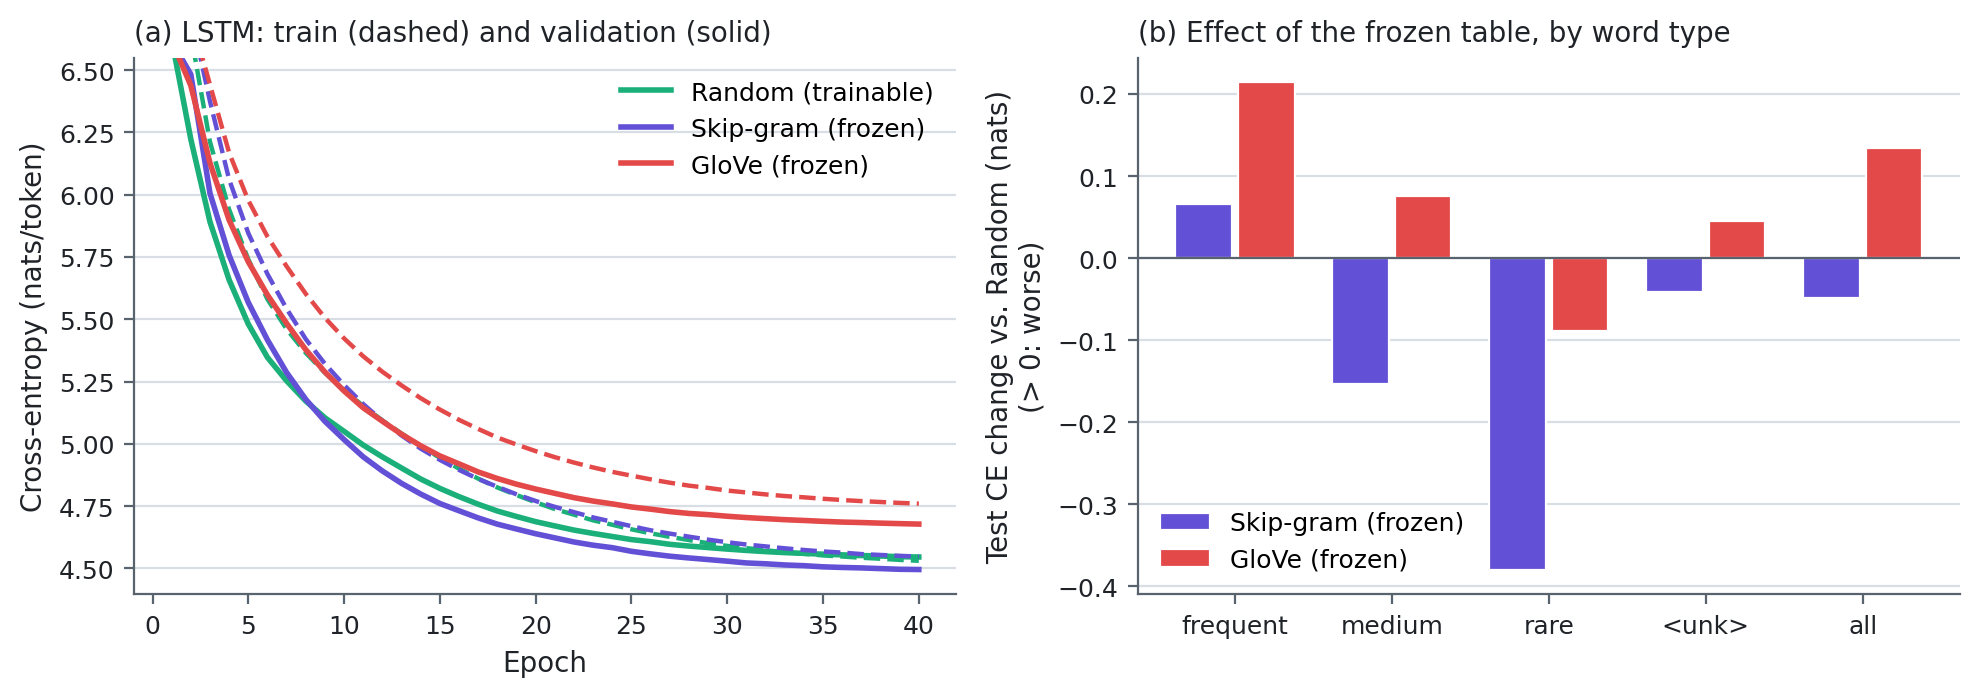

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

from IPython.display import Markdown, Image, display
display(Markdown(open("results/part2/summary.md").read().split("![Part II]")[0]))
display(Image("results/part2/fig_part2.png"))

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

from IPython.display import Markdown, display
display(Markdown(open("results/generation_part2/samples.md").read()))

/content


# Generated continuations (temperature 1.0, top-k 40, 50 new tokens, sample 0)

## Prompt 1 (neoplasms): *treatment of childhood &lt;unk&gt; diseases with recombinant interferon*

| Model | Continuation |
|---|---|
| Random (trainable) | alfa and alpha subunit and &lt;unk&gt; antibodies (tnf). the case of &lt;unk&gt; &lt;unk&gt; t cells is thought to be a potent &lt;unk&gt; and the presence of an inflammatory component that may involve a deletion from the regulation of chromosome &lt;num&gt;. the gene encoding the cellular reaction |
| Skip-gram (frozen) | alfa therapy for chemotherapy. the aim of this knowledge, the effect of &lt;num&gt; &lt;num&gt; yr old man died of an treatment for &lt;num&gt; years of patients with chronic ulcer leukemia after therapy: patients who died with fever after transplantation. in &lt;num&gt; patients receiving three weeks for |
| GloVe (frozen) | alfa in breast cancer. the pharmacokinetics and molecular ploidy of &lt;num&gt; (&lt;num&gt; &lt;num&gt; &lt;num&gt; yr ml) did not have a statistically significant difference in the serum alpha levels for serum levels as normal after onset of hepatitis virus b. in the first decade, one patient |

## Prompt 2 (digestive system diseases): *appraisal of gut lavage in the study of*

| Model | Continuation |
|---|---|
| Random (trainable) | the pathophysiology of &lt;unk&gt; &lt;unk&gt;. a patient with an abnormal extremity, or one patient developed a &lt;unk&gt;, the patient underwent &lt;unk&gt; syndrome and in a patient. an unusual model of cancer had been diagnosed by the use of surgical diagnosis. the most common lesion identified |
| Skip-gram (frozen) | the stomach. the &lt;unk&gt; and the &lt;unk&gt; and the type ii of the central nervous system, &lt;unk&gt;, the &lt;unk&gt; joint &lt;unk&gt; is also used to have &lt;unk&gt; in which is the possible mechanism for their cause of acute inflammation or the &lt;unk&gt;. by the role in |
| GloVe (frozen) | the united of &lt;unk&gt; &lt;unk&gt;, and &lt;num&gt; patients with chronic cholecystitis. these data suggest that the &lt;unk&gt; of the &lt;unk&gt; gene. however, of a &lt;num&gt; of &lt;num&gt; children with the presence of malignant melanoma was also only a highly significant. the incidence of tumor neoplasms |

## Prompt 3 (nervous system diseases): *expression of neural cell adhesion molecule in normal*

| Model | Continuation |
|---|---|
| Random (trainable) | . we report the efficacy of an unusual locus of murine liver lymphoma with &lt;num&gt; amino acids &lt;unk&gt;. with the &lt;unk&gt; of these areas of a large brain type, the polymerase chain reaction was determined by two fold, &lt;unk&gt; and &lt;num&gt; h of c. e &lt;num&gt; |
| Skip-gram (frozen) | . we measured the efficacy of acute interleukin colony (achr) receptors for &lt;num&gt; days after &lt;unk&gt;. an treatment of the hepatic mucosal, was measured by continuous in the incubation (&lt;num&gt; mg kg (a to &lt;num&gt; &lt;num&gt; g versus &lt;num&gt;) after the intravenous. |
| GloVe (frozen) | of human colon cells in children with inflammatory myeloma. although of plasma metabolism, both human &lt;unk&gt;, was not in the absence of &lt;num&gt;%, but all in the former b cell carcinomas were seen to result in &lt;num&gt;% of patients and three of one &lt;num&gt; |

## Prompt 4 (cardiovascular diseases): *bolus, front loaded, and accelerated thrombolytic*

| Model | Continuation |
|---|---|
| Random (trainable) | procedures (ct) than the control of the central aorta. the &lt;num&gt; children with obstructive hypertension in one series and two with normal and three patients with primary hyperparathyroidism were studied. in the treatment of the head and the disease in the same group, these other |
| Skip-gram (frozen) | during reperfusion and &lt;num&gt; minutes. in patients with severe heart failure, &lt;num&gt; per cent had a mean decrease on the incidence of ventricular function in &lt;num&gt; (&lt;num&gt; sd), the mean heart rate in &lt;num&gt;% and &lt;num&gt; (&lt;num&gt;) patients, an average follow |
| GloVe (frozen) | activity (r &lt;num&gt;). a case of this study, and &lt;num&gt; women with aids in the emergency department, this study was a major risk of treatment alone with a more two control of the group on a &lt;num&gt; year period. after &lt;num&gt; year follow up |

## Prompt 5 (general pathological conditions): *the importance of congenital hypertrophy of the retinal*

| Model | Continuation |
|---|---|
| Random (trainable) | artery. in &lt;num&gt; patients with congestive heart disease, &lt;num&gt; patients underwent a total of &lt;num&gt; patients from &lt;num&gt; patients with severe angina (&lt;num&gt;%). in the elderly patients (&lt;num&gt;%) compared with &lt;num&gt; patients and all died, the &lt;unk&gt; group were more |
| Skip-gram (frozen) | artery. in &lt;num&gt; patients with congenital aortic disease in &lt;num&gt; were asymptomatic. in the presence of cardiac artery disease was performed on the diagnosis of primary left ventricular valve regurgitation and cardiac failure (&lt;num&gt; per cent). the authors believe that the &lt;unk&gt; system is a |
| GloVe (frozen) | , in the treatment of this condition of the right of the esophagus. in a prospective study with the presence of a large left lesion were evaluated in the two groups of one, one of nine had the most of clinical staging. the &lt;unk&gt; showed that the |


## 9. Download the results (optional; they are also in Drive)

In [ ]:
%cd /content/drive/MyDrive/DSA4213/dsa4213-individual-assignment/

import glob, os, zipfile
out = "/content/part2_results.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for path in (glob.glob("results/part2/**", recursive=True)
                 + glob.glob("results/generation_part2/**", recursive=True)
                 + glob.glob("results/part2_lstm_*/*")):
        if os.path.isfile(path) and not path.endswith(".pt"):
            z.write(path)
from google.colab import files
files.download(out)

/content


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>